# The classical mean-size equation on one blast, and the term that drives it

**Question:** What does the classical equation predict for one blast, and which term drives it?

**Level 1: Fundamentals** · Needs: 01-the-data/02-geometry-reconstruction · Reading time: about 25 minutes

## Objectives

The oldest predictor in the ladder is a closed-form equation: Kuznetsov's 1973 mean size with the explosive-strength correction that Cunningham added. It needs no training data, only a geometry in metres and one number for the rock. This notebook runs it on a single blast, takes it apart into its factors, asks which of them drives the answer, and then runs it on a whole campaign to see how far a single blast can be trusted.

By the end you will have:

- built the predicted mean size of blast `En1` factor by factor and matched the engine's `kuznetsov_x50_m`;
- seen which factor carries most of the size, and how the prediction responds when each input is moved by 20 percent;
- predicted the 12 blasts of the Enusa campaign and scored the equation against the measurements and against a constant;
- understood why the one free number of the equation, the rock factor `A`, is the subject of the next notebook.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

The single setup cell below imports the packages, prints their installed versions so the output records which engine produced every number, sets the plotting style and defines `show_table`, a four-line helper that renders rows as a Markdown table because the notebook environment has no `pandas`.

In [1]:
# Imports, the pinned versions, the plotting style and one helper that renders a table
import dataclasses
from importlib.metadata import version

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def show_table(header, rows, left=1):
    # Render the rows as a Markdown table, the first `left` columns left-aligned and the others right-aligned
    lines = ["| " + " | ".join(header) + " |", "|" + ":---|" * left + "---:|" * (len(header) - left)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    text = "\n".join(lines)
    display({"text/markdown": text, "text/plain": text}, raw=True)

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

Two sources, both read from the engine, no file under `data/` needed:

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 12 Enusa blasts with measured `x50`, and the rest of the corpus | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The equation as printed, and the per-site rock factors | Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (Eqs. 2 and 3) | the equation is reproduced with citation | the engine's `kuznetsov_x50_m` and `SITE_ROCK_FACTOR` |

## Method

The mean fragment size in centimetres is

```
x50 = A * (V / Q)^0.8 * Q^(1/6) * (RWS / 115)^(-19/30)
```

with `V` the rock volume broken per hole (m3), `Q` the explosive mass in it (kg), `RWS` the relative weight strength of the explosive on the scale where ANFO is 100, and `A` the rock factor. The factor 115 is the strength of TNT on that scale, and the exponent -19/30 is Cunningham's correction as printed by Hudaverdi, Kulatilake and Kuzu 2010 (https://doi.org/10.1002/nag.957, Eq. 1) and by Amoako, Jha and Zhong 2022 (https://doi.org/10.3390/mining2020013, Eqs. 2 and 3).

Read the terms. Because `Q = Pf * V`, with `Pf` the powder factor, `V / Q` is the reciprocal of the powder factor: a richer charge gives a finer fragmentation. `Q^(1/6)` lets a larger hole fragment slightly coarser at the same powder factor. The strength term makes a stronger explosive finer. `A` is the rock: one number for the whole campaign.

### Step 1: the blast, its pattern and its rock factor

The cell loads the corpus, picks blast `En1` of Enusa and rebuilds its absolute pattern in metres with `reconstruct_pattern` (the previous topic's notebook 02). The rock factor of Enusa comes from the engine's table of per-site factors, `SITE_ROCK_FACTOR`; where that number comes from is the subject of the next notebook, so here it is a given. The table lists the four numbers the equation consumes, plus the measured size it will be compared with.

In [2]:
# Load the corpus, take blast En1 of Enusa and rebuild its pattern in metres
train = bf.load_training_corpus()
blast = next(b for b in train if b.blast_id == "En1")
pattern = bf.reconstruct_pattern(blast)
rock_factor = bf.SITE_ROCK_FACTOR[blast.site]
rows = [
    ("rock volume V (m3)", f"{pattern.rock_volume_m3:.3f}"),
    ("explosive mass Q (kg)", f"{pattern.charge_mass_kg:.3f}"),
    ("relative weight strength RWS (ANFO = 100)", f"{pattern.explosive.rws:g}"),
    ("rock factor A of Enusa", f"{rock_factor}"),
    ("measured x50 (m)", f"{blast.x50_m}"),
]
show_table(["quantity", "value for En1"], rows)

| quantity | value for En1 |
|:---|---:|
| rock volume V (m3) | 150.238 |
| explosive mass Q (kg) | 72.114 |
| relative weight strength RWS (ANFO = 100) | 100 |
| rock factor A of Enusa | 10.97 |
| measured x50 (m) | 0.37 |

The blast breaks 150.238 m3 of rock with 72.114 kg of ANFO, whose strength defines the 100 of the scale, so the strength term will turn out to be close to one. The rock factor is 10.97, and the measured mean size is 0.37 m. Keep one caution: the factor of 10.97 is not a measured property of the Enusa rock but a number recovered from published predictions for this very campaign, which makes any agreement with Enusa partly circular. The table says what goes into the equation; it does not say that the inputs are independent of the answer.

### Step 2: the equation, one factor per variable

Each factor of the equation gets its own variable, so every intermediate is visible: the rock factor, the volume term `(V/Q)^0.8`, the hole term `Q^(1/6)` and the strength term. Their product is the predicted size in centimetres. Because the factors multiply, the natural way to ask how much each one contributes is on a logarithmic scale: the share of `ln x50` that each factor carries adds up to 100 percent. The table shows the multipliers and those shares.

In [3]:
# The four factors of the equation, one variable each, and their product in centimetres and metres
V = pattern.rock_volume_m3
Q = pattern.charge_mass_kg
terms = {
    "A": rock_factor,
    "(V/Q)^0.8": (V / Q) ** 0.8,
    "Q^(1/6)": Q ** (1 / 6),
    "(RWS/115)^(-19/30)": (pattern.explosive.rws / 115.0) ** (-19.0 / 30.0),
}
x50_cm = np.prod(list(terms.values()))
rows = [(name, f"{value:.4f}", f"{np.log(value) / np.log(x50_cm):.1%}") for name, value in terms.items()]
show_table(["factor", "value (a multiplier)", "share of ln x50"], rows)
print(f"x50 = {x50_cm:.2f} cm = {x50_cm / 100:.4f} m")

| factor | value (a multiplier) | share of ln x50 |
|:---|---:|---:|
| A | 10.9700 | 63.3% |
| (V/Q)^0.8 | 1.7989 | 15.5% |
| Q^(1/6) | 2.0402 | 18.8% |
| (RWS/115)^(-19/30) | 1.0926 | 2.3% |

x50 = 43.99 cm = 0.4399 m


The four factors multiply to 43.99 cm, or 0.4399 m. The rock factor is 10.97 by itself and carries 63.3 percent of `ln x50`; the hole term, 2.0402, carries 18.8 percent; the volume term, 1.7989, carries 15.5 percent; and the strength correction, 1.0926, only 2.3 percent because the explosive is ANFO. So most of the answer is set by the one number that the corpus does not give, and the rest by the geometry. The table does not say whether the product is right, only how it is composed; the next cell compares it with the engine.

### Reproduction check: the hand product against the engine

`bf.kuznetsov_x50_m` implements the same equation. The cell calls it on the same pattern and compares it with the product built by hand, and prints the difference from the measurement. This is the notebook's only reproduction check: the other numbers of the engine and the committed artifacts of the bake are covered by the product's tests.

In [4]:
# The engine's own equation on the same pattern, against the hand product
engine = bf.kuznetsov_x50_m(pattern, rock_factor)
print("by hand equals the engine to 1e-12 m:", np.isclose(x50_cm / 100, engine, rtol=0, atol=1e-12))
print(f"engine: {engine:.4f} m | measured: {blast.x50_m} m | difference: {engine - blast.x50_m:+.3f} m")

by hand equals the engine to 1e-12 m: True
engine: 0.4399 m | measured: 0.37 m | difference: +0.070 m


The hand product and the engine agree to 1e-12 m, so the equation of this notebook is the equation of the engine and nothing hides inside it. The engine predicts 0.4399 m for a blast that measured 0.37 m, an excess of 0.070 m. One blast cannot say whether that miss is typical, which is why the last step runs the whole campaign.

### Step 3: which factor drives the size

The cell builds the predicted size up from 1 cm, multiplying one factor at a time: the bar of each factor runs from the running size before it to the running size after it, on a logarithmic axis where equal ratios have equal length. The dashed line marks the measured size of `En1`. Look at which bar is longest and where the running size crosses the measurement.

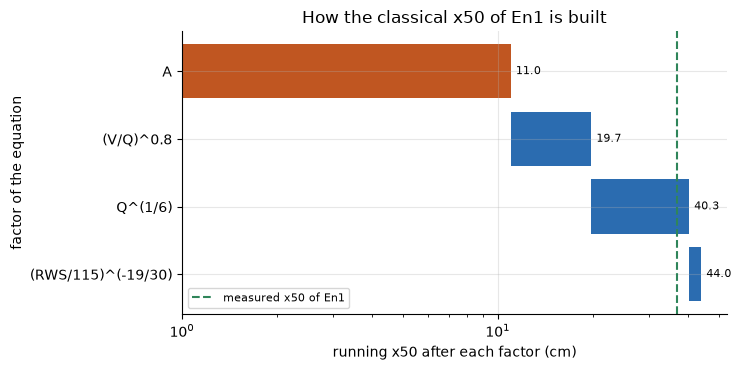

In [5]:
# Build x50 up factor by factor: the running product after each term, on a logarithmic axis
names = list(terms)
running = np.cumprod(list(terms.values()))
starts = np.concatenate([[1.0], running[:-1]])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(range(len(names)), running - starts, left=starts, color=["#c05621", "#2b6cb0", "#2b6cb0", "#2b6cb0"])
for position, total in enumerate(running):
    ax.text(total * 1.04, position, f"{total:.1f}", va="center", fontsize=8)
ax.axvline(blast.x50_m * 100, color="#2f855a", ls="--", label="measured x50 of En1")
ax.set_xscale("log")
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set_ylabel("factor of the equation")
ax.set_xlabel("running x50 after each factor (cm)")
ax.set_title("How the classical x50 of En1 is built")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

The rock factor alone takes the size from 1 cm to 11.0 cm, the longest bar by far. The volume term brings it to 19.7 cm, the hole term to 40.3 cm and the strength correction to 44.0 cm, just past the measured 37 cm. So the prediction crosses the measurement during the hole term, and it is the last two factors that push it over. The figure shows the composition of one blast and says nothing about another: the same bars for a blast of a different campaign would start from a different rock factor, and the rock factor is the term that nobody measured.

### Step 4: how the size responds to each input

Composition says how a size is built; sensitivity says what a change does. The cell moves one input at a time by minus 20 and plus 20 percent and records the relative change in the predicted size: the rock factor, the powder factor, the three lengths of the pattern (burden, spacing, bench height) and the strength of the explosive. The engine's `kuznetsov_x50_m` is called on every modified pattern; nothing is derived by hand. Look for which inputs move the answer by about as much as they move themselves, and which barely move it.

In [6]:
# Move one input at a time by -20 and +20 percent and record how the predicted x50 responds
base = bf.kuznetsov_x50_m(pattern, rock_factor)
fields = {"powder factor Pf": "powder_factor_kg_m3", "burden B": "burden_m",
          "spacing S": "spacing_m", "bench height H": "bench_height_m"}
response = {}
for k in (0.8, 1.2):
    response.setdefault("rock factor A", []).append(bf.kuznetsov_x50_m(pattern, rock_factor * k) / base - 1)
    for label, field in fields.items():
        moved = dataclasses.replace(pattern, **{field: getattr(pattern, field) * k})
        response.setdefault(label, []).append(bf.kuznetsov_x50_m(moved, rock_factor) / base - 1)
    stronger = dataclasses.replace(pattern.explosive, rws=pattern.explosive.rws * k)
    moved = dataclasses.replace(pattern, explosive=stronger)
    response.setdefault("explosive strength RWS", []).append(bf.kuznetsov_x50_m(moved, rock_factor) / base - 1)
rows = [(label, f"{low:+.1%}", f"{high:+.1%}") for label, (low, high) in response.items()]
show_table(["input moved", "at -20 %", "at +20 %"], rows)

| input moved | at -20 % | at +20 % |
|:---|---:|---:|
| rock factor A | -20.0% | +20.0% |
| powder factor Pf | +15.2% | -10.9% |
| burden B | -3.7% | +3.1% |
| spacing S | -3.7% | +3.1% |
| bench height H | -3.7% | +3.1% |
| explosive strength RWS | +15.2% | -10.9% |

The rock factor moves the size one for one, minus 20.0 and plus 20.0 percent. The powder factor and the explosive strength have identical effects, plus 15.2 percent when lowered and minus 10.9 percent when raised, because both enter with the same exponent, -19/30: with `Q = Pf * V`, the equation reduces to a power of the powder factor. The three lengths of the pattern move the size by only minus 3.7 and plus 3.1 percent, because they enter only through `Q^(1/6)`. So the geometry of the pattern barely changes the answer, while the charge and the rock do.

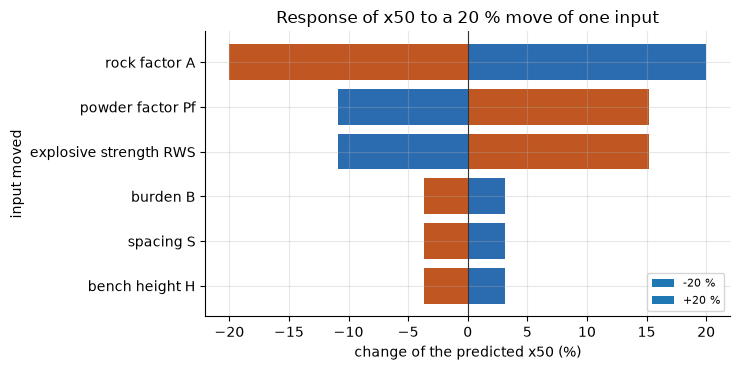

In [7]:
# The same response as a tornado chart, the most influential input on top
order = sorted(response, key=lambda label: -max(abs(v) for v in response[label]))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for position, label in enumerate(order):
    low, high = response[label]
    ax.barh(position, low * 100, color="#c05621")
    ax.barh(position, high * 100, color="#2b6cb0")
ax.axvline(0, color="#333", lw=0.8)
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.set_ylabel("input moved")
ax.set_xlabel("change of the predicted x50 (%)")
ax.set_title("Response of x50 to a 20 % move of one input")
ax.barh([], [], color="#c05621", label="-20 %")
ax.barh([], [], color="#2b6cb0", label="+20 %")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

The tornado chart orders the inputs by how far they move the predicted size, orange for a decrease of the input and blue for an increase. The rock factor stretches furthest in both directions, the powder factor and the explosive strength come next with the same lopsided shape, and burden, spacing and bench height are three identical short bars. The picture shows the response of one blast in the neighbourhood of its own design; it does not show how the responses interact, and it does not say which inputs an engineer can actually change: the rock factor cannot be chosen, the powder factor and the pattern can.

### Step 5: the whole campaign

One blast proves nothing, so the cell predicts all 12 Enusa blasts with the engine's `Kuznetsov` predictor and scores them with `bf.score`, which names each statistic. The reference is the null model that predicts the mean of the training corpus for every blast and uses no input at all: a predictor that cannot beat a constant has no skill to report. The table prints both, with the two statistics that this literature calls r2 under their own names: the squared correlation, and the variance explained about the identity line.

In [8]:
# Predict the 12 Enusa blasts and score the equation, with the training mean as the reference
enusa = [b for b in train if b.site == "Enusa"]
predictions = bf.Kuznetsov().predict(enusa)
score = bf.score(enusa, predictions, method="kuznetsov")
null = bf.null_model_score(enusa, training_mean_m=bf.training_mean(train))
rows = []
for label, s in (("classical equation", score), ("training mean (null)", null)):
    r2 = f"{s.pearson_r2:.3f}" if np.isfinite(s.pearson_r2) else "-"
    errors = (f"{s.rmse_m:.3f}", f"{s.bias_m:+.3f}", f"{s.mae_m:.3f}", f"{s.mape_pct:.1f}")
    rows.append((label, *errors, r2, f"{s.r2_identity:.3f}"))
header = ["predictor", "RMSE (m)", "bias (m)", "MAE (m)", "MAPE (%)", "Pearson r2",
          "r2 about identity"]
show_table(header, rows)
distinct = len({round(p.x50_m, 6) for p in predictions})
print("blasts scored:", score.n_scored, "| distinct predicted values:", distinct)
values = [round(p.x50_m, 6) for p in predictions]
common = max(set(values), key=values.count)
sharing = [b.x50_m for b, v in zip(enusa, values) if v == common]
span = f"{min(sharing):.2f} to {max(sharing):.2f}"
print(f"{len(sharing)} blasts share one predicted value; their measured sizes (m): {span}")
over = sum(p.x50_m > b.x50_m for p, b in zip(predictions, enusa))
print("blasts predicted coarser than measured:", over, "of", len(enusa))

| predictor | RMSE (m) | bias (m) | MAE (m) | MAPE (%) | Pearson r2 | r2 about identity |
|:---|---:|---:|---:|---:|---:|---:|
| classical equation | 0.147 | +0.105 | 0.122 | 34.9 | 0.017 | -1.643 |
| training mean (null) | 0.130 | -0.093 | 0.100 | 22.7 | - | -1.066 |

blasts scored: 12 | distinct predicted values: 5
5 blasts share one predicted value; their measured sizes (m): 0.33 to 0.46
blasts predicted coarser than measured: 10 of 12


The equation misses by 0.147 m RMSE and predicts coarser than measured on average (bias +0.105 m), 10 of the 12 blasts predicted coarser than measured. The squared correlation is 0.017, so the predicted sizes barely follow the measured ones, and the variance explained about the identity line is -1.643, worse than a constant. The null model, which uses no input, is closer: RMSE 0.130 m and -1.066. The equation also returns only 5 distinct values for 12 blasts, because blasts with the same pattern get the same answer, while the measured sizes differ. This is a single campaign with little spread, which hurts every statistic, but it means this table gives no evidence of skill.

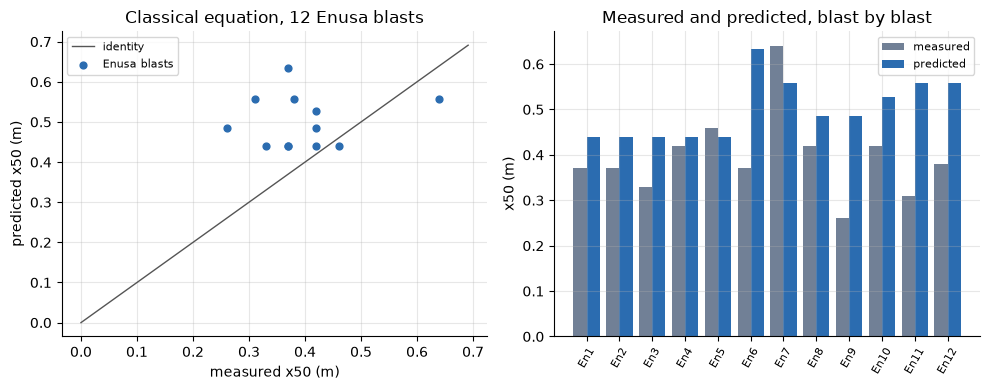

In [9]:
# Left: predicted against measured x50 for the 12 blasts. Right: both sizes blast by blast
measured = np.array([b.x50_m for b in enusa])
predicted = np.array([p.x50_m for p in predictions])
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
limit = max(measured.max(), predicted.max()) * 1.08
left.plot([0, limit], [0, limit], color="#555", lw=1, label="identity")
left.scatter(measured, predicted, s=24, color="#2b6cb0", label="Enusa blasts")
left.set_xlabel("measured x50 (m)")
left.set_ylabel("predicted x50 (m)")
left.set_title("Classical equation, 12 Enusa blasts")
left.legend(fontsize=8)
positions = np.arange(len(enusa))
right.bar(positions - 0.2, measured, width=0.4, color="#718096", label="measured")
right.bar(positions + 0.2, predicted, width=0.4, color="#2b6cb0", label="predicted")
right.set_xticks(positions, [b.blast_id for b in enusa], rotation=60, fontsize=8)
right.set_ylabel("x50 (m)")
right.set_title("Measured and predicted, blast by blast")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

The left panel plots predicted against measured size with the identity line: almost every point sits above it, and the cloud has no slope to speak of. The right panel puts both sizes side by side blast by blast, and shows the plateau: En1 to En5 share one predicted value while their measured sizes range from 0.33 to 0.46 m. The figure shows that, inside Enusa, the equation misses the variation that the campaign actually has. It does not show how the equation does across campaigns, where the rock factor changes from site to site; that comparison, and the question of where the factor comes from, are the next notebook.

## Results

**Answer:** For blast `En1` the classical equation predicts 0.4399 m against a measured 0.37 m, and the term that drives it is the rock factor: `A = 10.97` carries 63.3 percent of `ln x50`, against 15.5 and 18.8 percent for the volume and hole terms and 2.3 percent for the strength correction. The response confirms it: moving `A` by 20 percent moves the size by 20 percent, the powder factor and the explosive strength move it by 15.2 and 10.9 percent in the two directions, and any length of the pattern by only 3.7 or 3.1 percent. Over the 12 Enusa blasts the equation has an RMSE of 0.147 m, a bias of +0.105 m, and a variance explained about the identity line of -1.643, against 0.130 m and -1.066 for a constant.

**What follows.** A decision that depends on this equation depends on a number nobody measured. The pattern, the one input an engineer can change freely, has little leverage on its answer, while the powder factor has a lot. And a single blast says little: the campaign table is the honest summary.

**What this notebook does not show.** The factor of Enusa was recovered from published predictions for this very campaign, so even the poor agreement is flattered by borrowed knowledge. One campaign has little spread, so every statistic of this table is harsh. And nothing here compares the equation with a campaign it has never seen: that is the question of topic 04, and the next notebook opens the rock factor.

## Summary

- The equation is four multipliers: the rock factor, a volume term, a hole-size term and a strength correction.
- The rock factor carries 63.3 percent of `ln x50` for `En1`, and the pattern's lengths barely matter (a 20 percent move of one length moves the size by 3.7 or 3.1 percent).
- The engine and a hand product agree to 1e-12 m, and the engine predicts 0.4399 m for a blast that measured 0.37 m.
- On the 12 Enusa blasts the equation is no closer than a constant: RMSE 0.147 m against 0.130 m.
- Next: notebook 02 opens the rock factor, the one number the equation cannot compute from the table.

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (Eq. 1, the corpus)
- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (Eqs. 2 and 3, the equation and its units)
- Kuznetsov 1973 and Cunningham 1983, 1987 and 2005 are the originals of the equation and its corrections; the SDD records that their primary texts were not held, so this notebook cites them only through the two papers above.
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/